In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt, savgol_filter, find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "20261118"
FIG = ROOT / "figures" / "20261118"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

# Runs that show the full 4-line structure (the two ch1 runs have a ~-0.1 V offset signal and almost no contrast).
RUNS = {
    "1026-2diode-withpump":    "2 diodes, with pump",
    "1027-2diode-withoutpump": "2 diodes, no pump",
    "1028-ch2-withpump":       "ch2, with pump",
    "1028-ch2-withoutpump":    "ch2, no pump",
}
MAIN = "1027-2diode-withoutpump"   # clean Doppler profile -> used for the step-by-step figures + calibration

def load(run):
    f = next((DATA / run).glob("*_HighRes.csv"))
    t, scan, sig = np.loadtxt(f, delimiter=",", comments="%").T
    return t, scan, sig

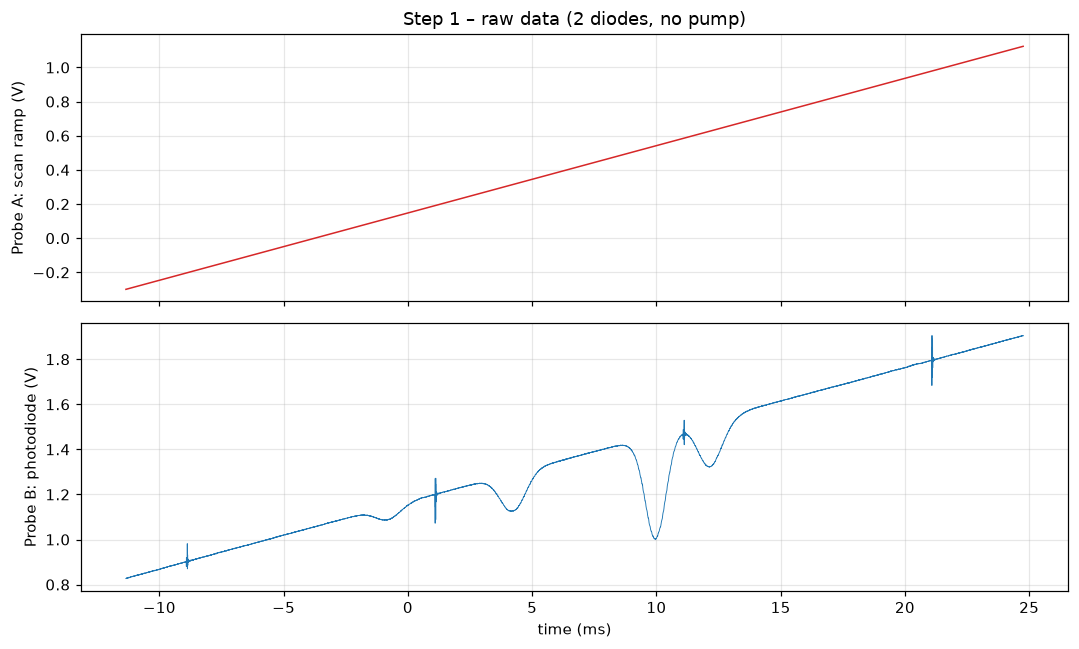

In [2]:
t, scan, sig = load(MAIN)
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(t * 1e3, scan, "tab:red", lw=1); ax[0].set_ylabel("Probe A: scan ramp (V)")
ax[1].plot(t * 1e3, sig, lw=.6); ax[1].set_ylabel("Probe B: photodiode (V)"); ax[1].set_xlabel("time (ms)")
ax[0].set_title(f"Step 1 – raw data ({RUNS[MAIN]})")
save(fig, "01_raw")

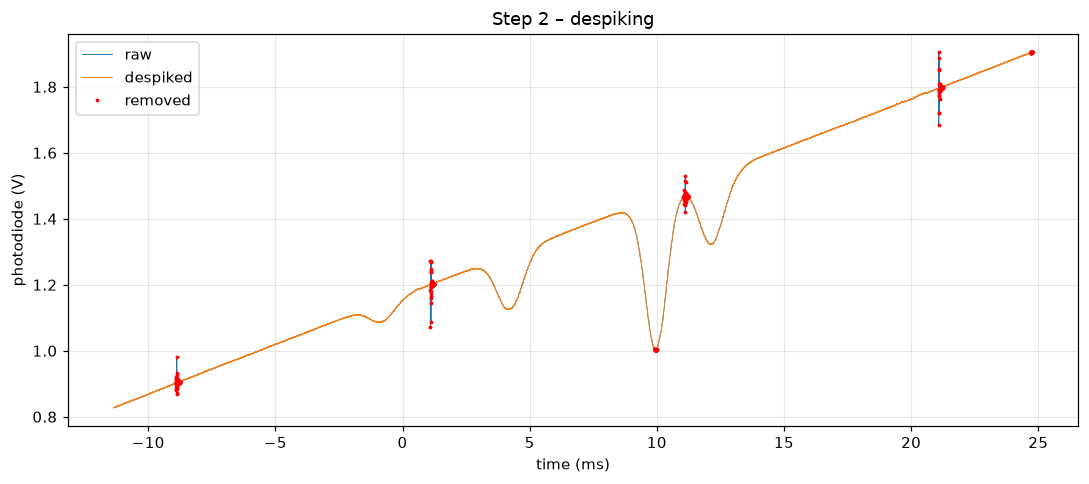

In [3]:
def despike(sig, k=101, nsigma=6):
    med = medfilt(sig, k)
    r = sig - med
    mad = 1.4826 * np.median(np.abs(r))
    bad = np.abs(r) > nsigma * mad
    out = sig.copy(); out[bad] = med[bad]
    return out, bad

clean, bad = despike(sig)
print(f"{bad.sum()} of {sig.size} samples replaced")
fig, ax = plt.subplots()
ax.plot(t * 1e3, sig, lw=.6, label="raw")
ax.plot(t * 1e3, clean, lw=.6, label="despiked")
ax.plot(t[bad] * 1e3, sig[bad], "r.", ms=3, label="removed")
ax.set(xlabel="time (ms)", ylabel="photodiode (V)", title="Step 2 – despiking"); ax.legend()
save(fig, "02_despike")

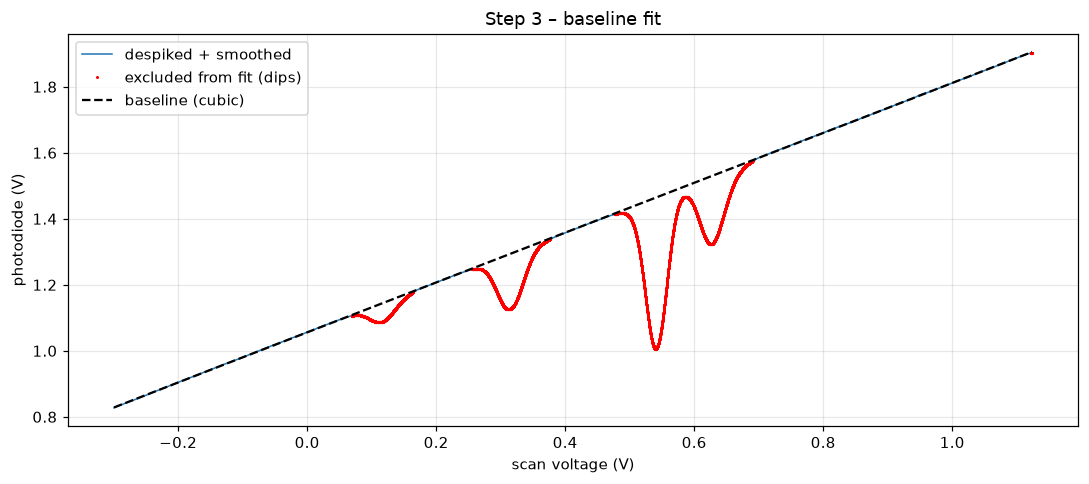

In [4]:
def smooth(y, win=301):          # 301 samples ~ 0.66 ms ~ 0.35 GHz: well below the Doppler linewidth
    return savgol_filter(y, win, 3)

def fit_baseline(x, y, deg=3, tol=0.002, iters=30):
    xn = (x - x.mean()) / np.ptp(x)
    mask = np.ones_like(xn, bool)
    for _ in range(iters):
        coef = np.polyfit(xn[mask], y[mask], deg)
        base = np.polyval(coef, xn)
        mask = y >= base - tol
    return base, mask

smoothed = smooth(clean)
base, mask = fit_baseline(scan, smoothed)
fig, ax = plt.subplots()
ax.plot(scan, smoothed, lw=1, label="despiked + smoothed")
ax.plot(scan[~mask], smoothed[~mask], "r.", ms=2, label="excluded from fit (dips)")
ax.plot(scan, base, "k--", label="baseline (cubic)")
ax.set(xlabel="scan voltage (V)", ylabel="photodiode (V)", title="Step 3 – baseline fit"); ax.legend()
save(fig, "03_baseline")

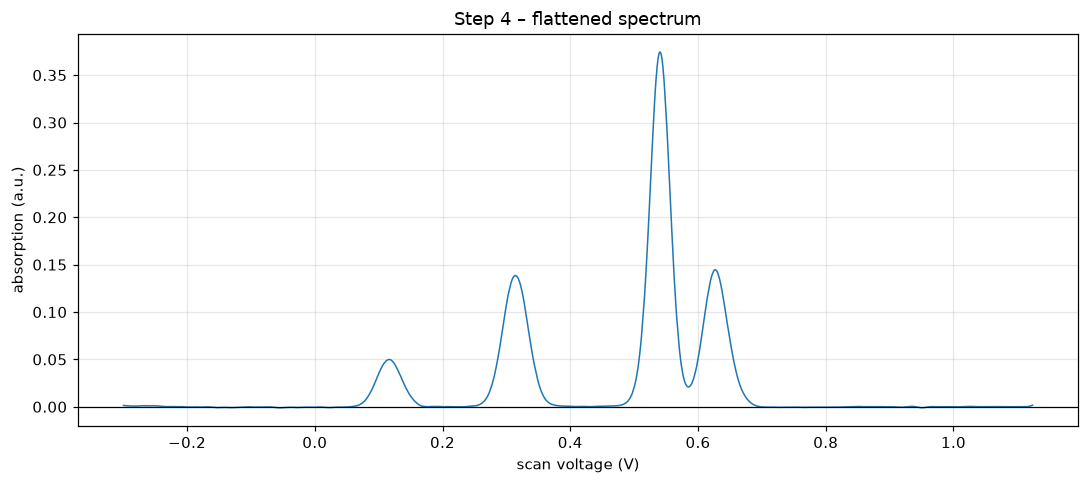

In [5]:
def flatten(smoothed, base):
    return -np.log(smoothed / base)

absorb = flatten(smoothed, base)
fig, ax = plt.subplots()
ax.plot(scan, absorb, lw=1); ax.axhline(0, color="k", lw=.8)
ax.set(xlabel="scan voltage (V)", ylabel="absorption (a.u.)", title="Step 4 – flattened spectrum")
save(fig, "04_flattened")
print("baseline noise (rms of quiet region): %.1e" % absorb[scan > scan.max() - 0.3].std())

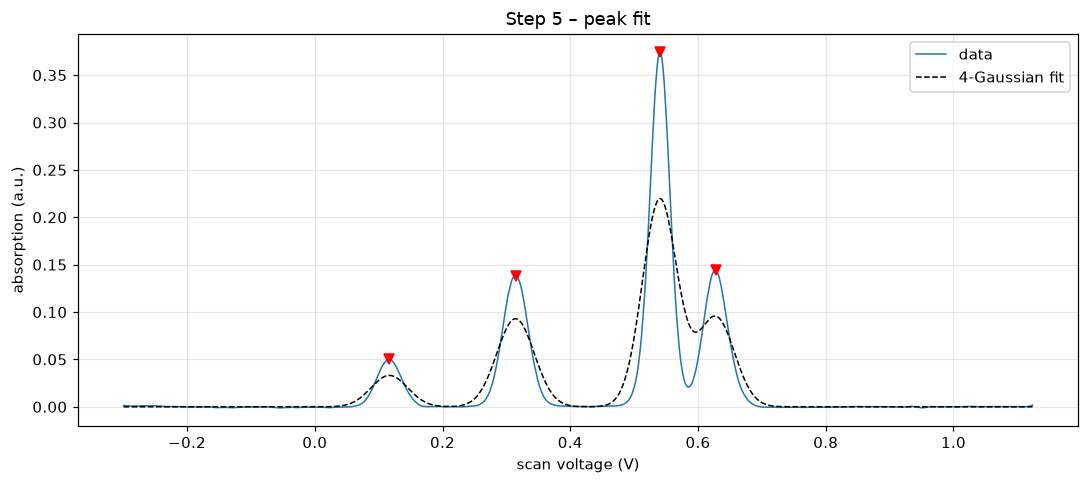

In [6]:
LINES = ["87Rb F=2", "85Rb F=3", "85Rb F=2", "87Rb F=1"]       # increasing frequency
# Literature position of each ground-state line relative to the 85Rb hyperfine centroid (GHz).
# E_hfs (Steck): 85: F=2 -1.2649, F=3 +1.7708 ; 87: F=1 -4.2717, F=2 +2.5630 ; isotope shift 87-85 = +0.0781
# A higher ground level lowers the transition frequency, so nu = iso_shift - E_ground.
LIT_GHZ = np.array([0.0781 - 2.5630, -1.7708, +1.2649, 0.0781 + 4.2717])
STYLE = {"87Rb F=2": ("tab:blue", "red"), "85Rb F=3": ("saddlebrown", "black"),
         "85Rb F=2": ("darkorange", "black"), "87Rb F=1": ("limegreen", "red")}  # (marker, label colour) as reference fig

def gauss4(x, off, *p):
    y = off + 0 * x
    for a, c, w in zip(p[0::3], p[1::3], p[2::3]):
        y = y + a * np.exp(-0.5 * ((x - c) / w) ** 2)
    return y

def fit_peaks(x, y, sigma_samples=250):
    # Heavy Gaussian smoothing (~0.55 ms) keeps only the Doppler envelope, so narrow sub-Doppler spikes
    # in the "with pump" runs cannot confuse the peak finder or the fit.
    ys = gaussian_filter1d(y, sigma_samples)
    pk, _ = find_peaks(ys, prominence=0.008)
    pk = pk[np.argsort(-x[pk])]                      # decreasing voltage = increasing frequency
    assert len(pk) == 4, f"expected 4 peaks, found {len(pk)}"
    p0 = [0] + [v for i in pk for v in (ys[i], x[i], 0.05)]
    popt, _ = curve_fit(gauss4, x, ys, p0=p0)
    cen, wid = popt[2::3], np.abs(popt[3::3])
    heights = np.array([y[np.argmin(np.abs(x - c))] for c in cen])   # data value at each centre (for the markers)
    return heights, cen, wid, popt, ys

amps, cen, wid, popt, fitted_on = fit_peaks(scan, absorb)
for n, a, c, w in zip(LINES, amps, cen, wid):
    print(f"{n}: centre {c:.4f} V, height {a:.3f}, sigma {w*1e3:.1f} mV")

fig, ax = plt.subplots()
ax.plot(scan, absorb, lw=1, label="data"); ax.plot(scan, gauss4(scan, *popt), "k--", lw=1, label="4-Gaussian fit")
ax.plot(cen, amps, "rv"); ax.set(xlabel="scan voltage (V)", ylabel="absorption (a.u.)", title="Step 5 – peak fit"); ax.legend()
save(fig, "05_peakfit")

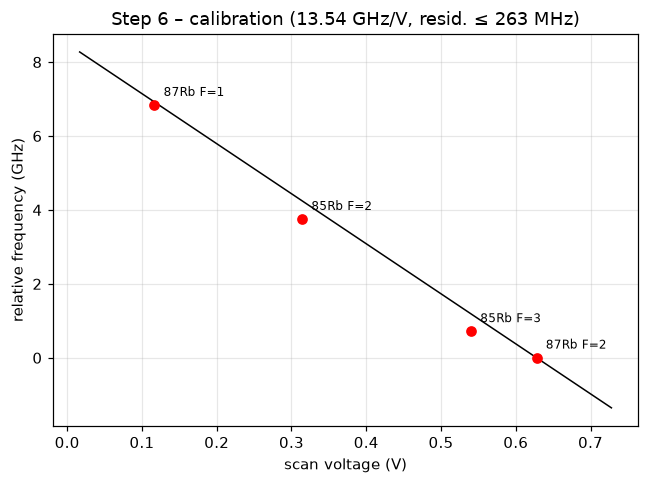

In [7]:
k, c0 = np.polyfit(cen, LIT_GHZ, 1)        # GHz = k * V + c0
resid_MHz = (np.polyval([k, c0], cen) - LIT_GHZ) * 1e3
print(f"scan slope: {k:.3f} GHz/V  ({1/abs(k):.3f} V/GHz);  residuals (MHz): {np.round(resid_MHz)}")

def to_relfreq(v): return k * (v - cen[0])   # relative frequency (GHz); 0 = fitted 87Rb F=2 peak of the main run

fig, ax = plt.subplots(figsize=(6, 4.5))
vv = np.linspace(cen.min() - .1, cen.max() + .1, 10)
ax.plot(vv, to_relfreq(vv), "k-", lw=1); ax.plot(cen, LIT_GHZ - LIT_GHZ[0], "ro")
for n, x_, y_ in zip(LINES, cen, LIT_GHZ - LIT_GHZ[0]): ax.annotate(n, (x_, y_), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set(xlabel="scan voltage (V)", ylabel="relative frequency (GHz)",
       title=f"Step 6 – calibration ({abs(k):.2f} GHz/V, resid. ≤ {np.abs(resid_MHz).max():.0f} MHz)")
save(fig, "06_calibration")

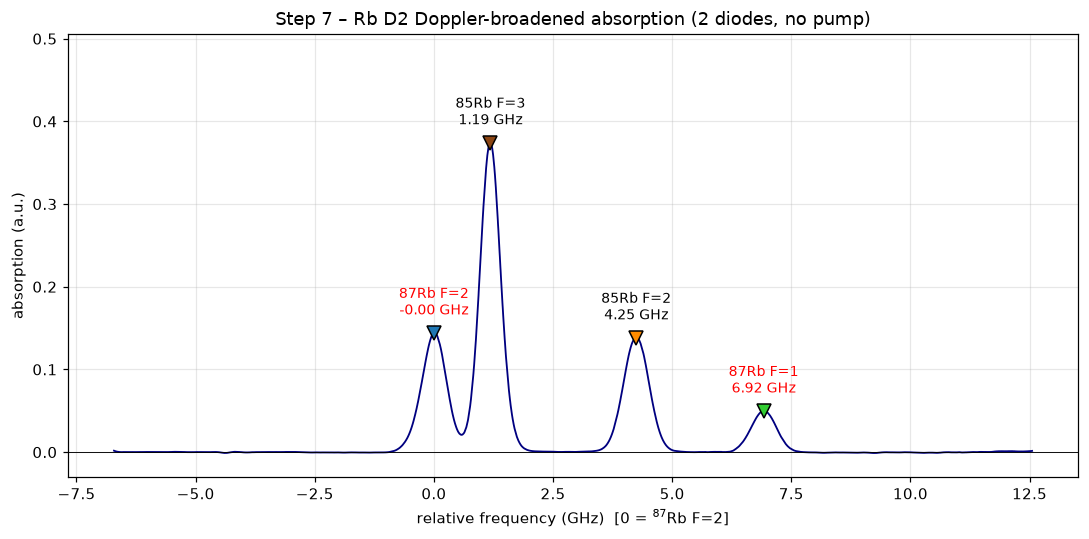

In [8]:
def final_plot(ax, x_scan, y, amps, cen, title=None):
    f = to_relfreq(x_scan)
    ax.plot(f, y, "navy", lw=1.2); ax.axhline(0, color="k", lw=.6)
    for n, a, cc in zip(LINES, amps, cen):
        fc = to_relfreq(cc); mk, lc = STYLE[n]
        ax.plot(fc, a * 1.0, "v", color=mk, ms=9, mec="k")
        ax.annotate(f"{n}\n{fc:.2f} GHz", (fc, a), textcoords="offset points", xytext=(0, 12),
                    ha="center", fontsize=9, color=lc)
    ax.set(xlabel="relative frequency (GHz)  [0 = $^{87}$Rb F=2]", ylabel="absorption (a.u.)")
    ax.set_ylim(-0.03, y.max() * 1.35)
    if title: ax.set_title(title)

fig, ax = plt.subplots(figsize=(10, 5))
final_plot(ax, scan, absorb, amps, cen, f"Step 7 – Rb D2 Doppler-broadened absorption ({RUNS[MAIN]})")
save(fig, "07_final")

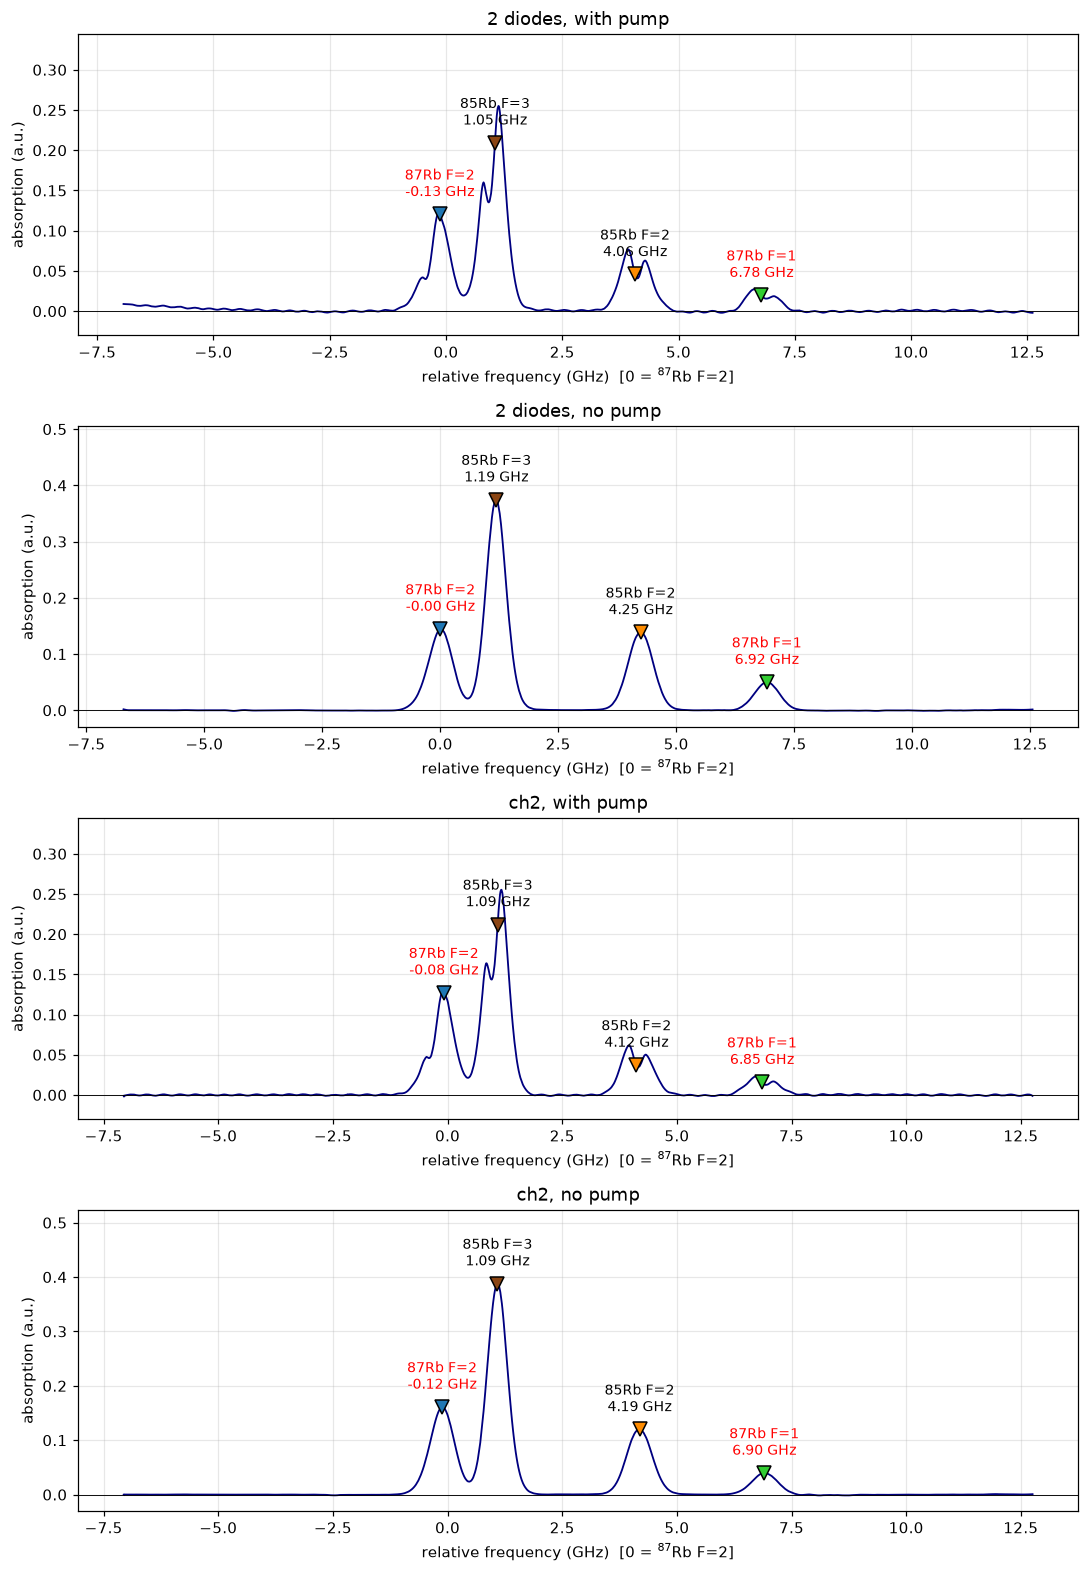

In [9]:
def process(run):
    t, scan, sig = load(run)
    clean, _ = despike(sig)
    sm = smooth(clean)
    base, _ = fit_baseline(scan, sm)
    ab = flatten(sm, base)
    amps, cen, *_ = fit_peaks(scan, ab)
    return scan, ab, amps, cen

fig, axes = plt.subplots(len(RUNS), 1, figsize=(10, 3.6 * len(RUNS)))
for ax, run in zip(axes, RUNS):
    scan_, ab_, a_, c_ = process(run)
    final_plot(ax, scan_, ab_, a_, c_, RUNS[run])
    print(run, "peak freq (GHz):", np.round(to_relfreq(c_), 2))
save(fig, "08_all_runs")

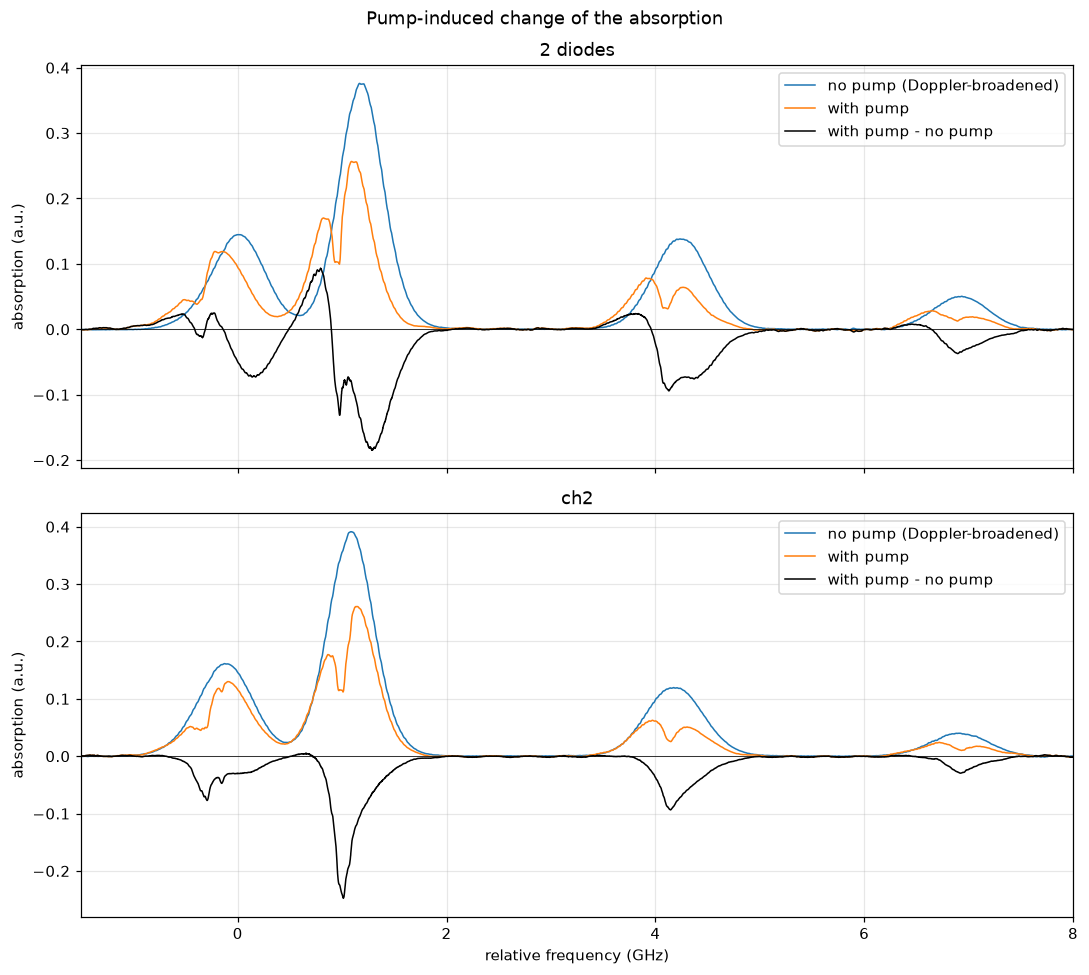

In [10]:
# ---- Doppler-free part: pump on vs off -------------------------------------------------------------
PAIRS = {"2 diodes": ("1026-2diode-withpump", "1027-2diode-withoutpump"),
         "ch2":      ("1028-ch2-withpump",    "1028-ch2-withoutpump")}

def process_hr(run, win=31):
    """Same pipeline as above, but only light smoothing (win=31 samples ~ 0.07 ms ~ 35 MHz) so narrow features survive."""
    _, scan, sig = load(run)
    clean, _ = despike(sig)
    base, _ = fit_baseline(scan, smooth(clean))      # baseline still from the heavily smoothed trace
    return scan, -np.log(savgol_filter(clean, win, 3) / base)

fig, axes = plt.subplots(len(PAIRS), 1, figsize=(10, 4.5 * len(PAIRS)), sharex=True)
for ax, (name, (pump, nopump)) in zip(axes, PAIRS.items()):
    v, a_p = process_hr(pump); v2, a_n = process_hr(nopump)
    a_n = np.interp(v, v2, a_n)                      # put both runs on the same scan-voltage grid
    f = to_relfreq(v)
    ax.plot(f, a_n, lw=1, label="no pump (Doppler-broadened)")
    ax.plot(f, a_p, lw=1, label="with pump")
    ax.plot(f, a_p - a_n, "k", lw=1, label="with pump - no pump")
    ax.axhline(0, color="k", lw=.5); ax.set_xlim(-1.5, 8); ax.set_ylabel("absorption (a.u.)"); ax.set_title(name); ax.legend()
axes[-1].set_xlabel("relative frequency (GHz)")
fig.suptitle("Pump-induced change of the absorption")
save(fig, "09_pump_difference")

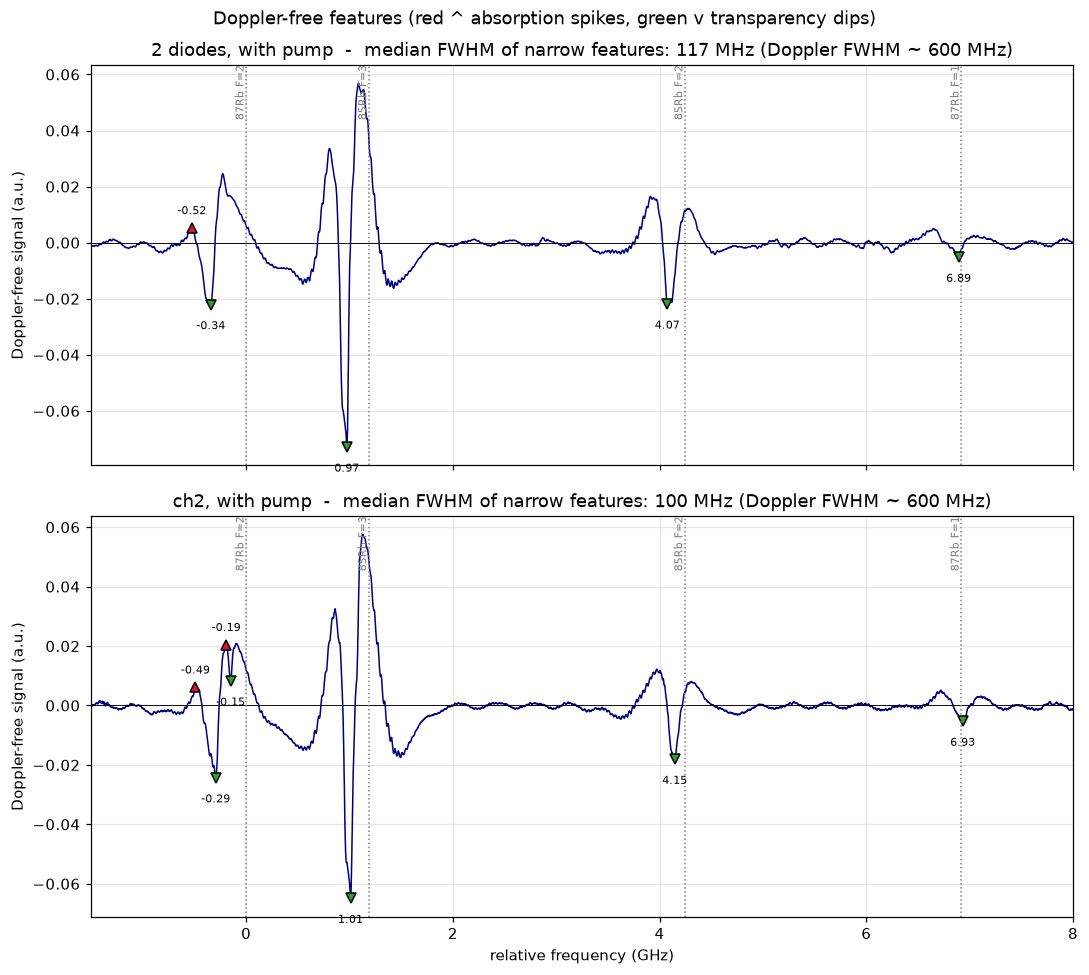

In [11]:
# ---- Isolate the Doppler-free features: subtract the Doppler envelope (high-pass) ---------------------
def doppler_free(v, a, sigma_samples=100):
    """a minus its own Doppler envelope (Gaussian smoothing ~ 0.12 GHz, i.e. wider than the narrow features, narrower than the Doppler lines)  ->  only the narrow structure remains."""
    return a - gaussian_filter1d(a, sigma_samples)

def narrow_features(f, d, prom=0.006):
    """Narrow transparency dips (d<0) and absorption spikes (d>0) with FWHM in MHz."""
    out = []
    for sign in (+1, -1):
        pk, pr = find_peaks(sign * d, prominence=prom, width=3)
        w = pr["widths"] * np.abs(np.median(np.diff(f))) * 1e3          # FWHM in MHz
        out += [(f[i], d[i], sign, wi) for i, wi in zip(pk, w) if wi < 150]
    return sorted(out)

fig, axes = plt.subplots(len(PAIRS), 1, figsize=(10, 4.5 * len(PAIRS)), sharex=True)
FEATURES = {}
for ax, (name, (pump, _)) in zip(axes, PAIRS.items()):
    v, a_p = process_hr(pump)
    f = to_relfreq(v); d = doppler_free(v, a_p)
    feats = FEATURES[name] = narrow_features(f, d)
    ax.plot(f, d, "navy", lw=1); ax.axhline(0, color="k", lw=.6)
    for fc, dc, s, w in feats:
        ax.plot(fc, dc, "^" if s > 0 else "v", color="crimson" if s > 0 else "tab:green", ms=7, mec="k")
        ax.annotate(f"{fc:.2f}", (fc, dc), textcoords="offset points", xytext=(0, 9 if s > 0 else -16), ha="center", fontsize=7)
    for n, c in zip(LINES, cen):                     # Doppler line centres for reference
        ax.axvline(to_relfreq(c), color="grey", ls=":", lw=1); ax.text(to_relfreq(c), ax.get_ylim()[1], n, rotation=90, va="top", ha="right", fontsize=7, color="grey")
    ax.set_xlim(-1.5, 8); ax.set_ylabel("Doppler-free signal (a.u.)")
    ax.set_title(f"{name}, with pump  -  median FWHM of narrow features: {np.median([x[3] for x in feats]):.0f} MHz (Doppler FWHM ~ 600 MHz)")
axes[-1].set_xlabel("relative frequency (GHz)")
fig.suptitle("Doppler-free features (red ^ absorption spikes, green v transparency dips)")
save(fig, "10_doppler_free")

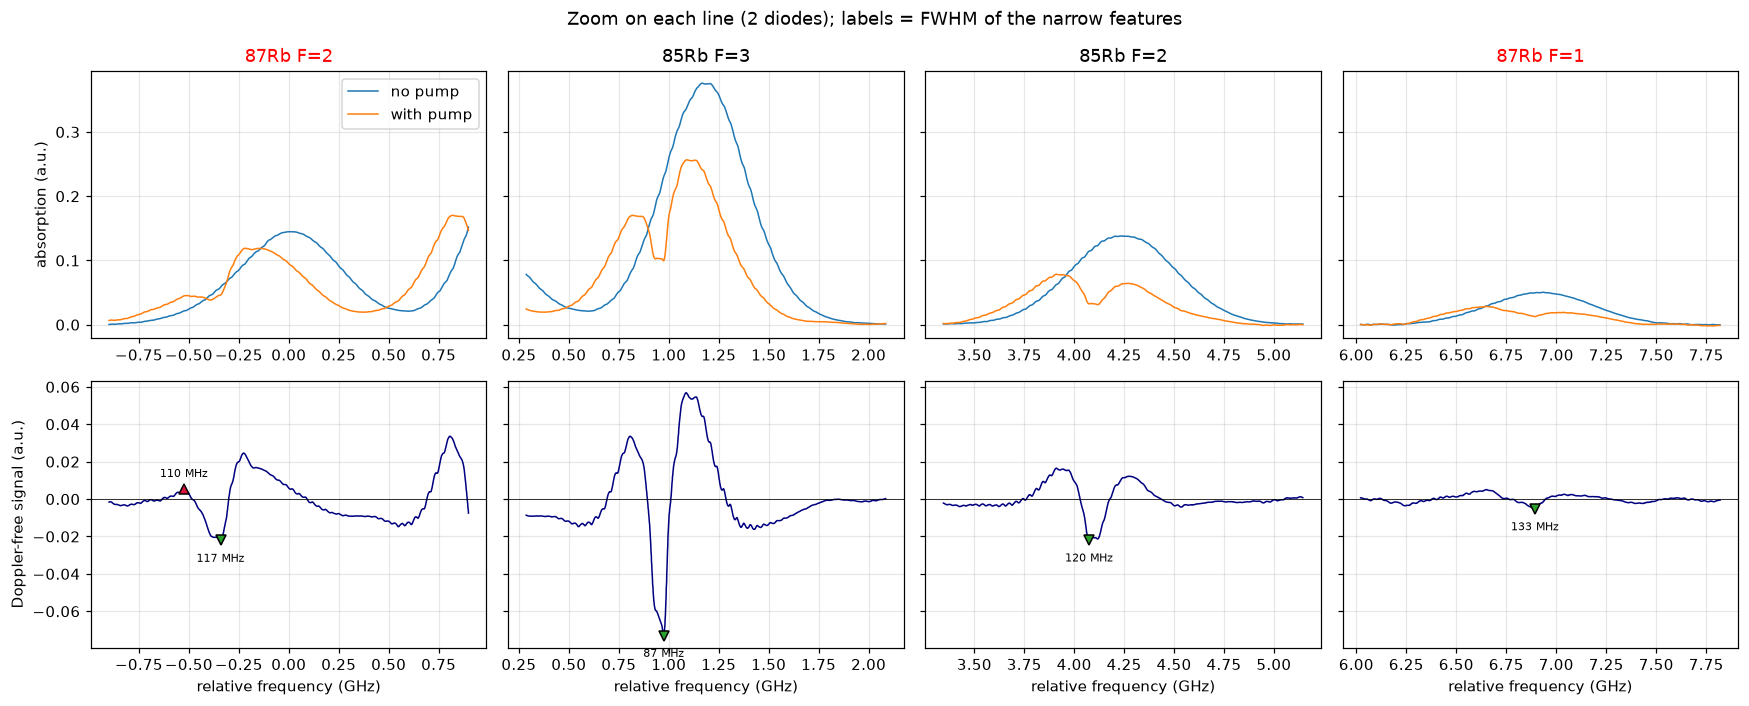

In [12]:
# ---- Zoom on each Rb line: Doppler-broadened (no pump) vs Doppler-free structure (pump) ----------------
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharey="row")
name = "2 diodes"; pump, nopump = PAIRS[name]
v, a_p = process_hr(pump); v2, a_n = process_hr(nopump); a_n = np.interp(v, v2, a_n)
f = to_relfreq(v); d = doppler_free(v, a_p)
for j, (n, c) in enumerate(zip(LINES, cen)):
    fc = to_relfreq(c); sel = np.abs(f - fc) < 0.9
    top, bot = axes[0, j], axes[1, j]
    top.plot(f[sel], a_n[sel], lw=1, label="no pump"); top.plot(f[sel], a_p[sel], lw=1, label="with pump")
    top.set_title(n, color=STYLE[n][1]); bot.plot(f[sel], d[sel], "navy", lw=1); bot.axhline(0, color="k", lw=.5)
    for x, dc, s, w in FEATURES[name]:
        if abs(x - fc) < 0.9:
            bot.plot(x, dc, "^" if s > 0 else "v", color="crimson" if s > 0 else "tab:green", ms=7, mec="k")
            bot.annotate(f"{w:.0f} MHz", (x, dc), textcoords="offset points", xytext=(0, 8 if s > 0 else -14), ha="center", fontsize=7)
    bot.set_xlabel("relative frequency (GHz)")
axes[0, 0].set_ylabel("absorption (a.u.)"); axes[1, 0].set_ylabel("Doppler-free signal (a.u.)"); axes[0, 0].legend()
fig.suptitle(f"Zoom on each line ({name}); labels = FWHM of the narrow features")
save(fig, "11_zoom_lines")